## Laboratorio - Gestión de tareas con Max-Heap y Cola de Prioridad

**Instrucción:** completa esta plantilla con el desarrollo del laboratorio.


In [ ]:
# LABORATORIO 
nombre_estudiante = "JULIANA ANDREA SEGURA MELO, FELIPE BELTRAN, JUAN SEBASTIAN PULGARIN  " 

carnet = 1000110169, 1000116566, 1000103178 


## 1) Descripción del problema **[1 pts]**



Un centro de cómputo recibe diferentes tareas que deben ser ejecutadas por sus servidores. Cada tarea contiene un código que la identifica, un nombre que describe su función y una prioridad numérica que determina el orden en el que debe ser procesada. Actualmente, organizar estas tareas puede resultar complicado cuando se necesita atender primero las que tienen mayor importancia.

Para solucionar este problema, se propone desarrollar un programa en Python que permita registrar y administrar las tareas mediante una estructura de datos llamada Max-Heap, implementada utilizando un arreglo. Esta estructura permite mantener la tarea de mayor prioridad en la raíz, facilitando su consulta y extracción.

El programa permitirá registrar las tareas ingresadas por el usuario, construir un Max-Heap a partir de sus prioridades, consultar y procesar la tarea de mayor prioridad e insertar nuevas tareas sin perder las propiedades de la estructura. Adicionalmente, se implementará el algoritmo HeapSort para ordenar las prioridades de menor a mayor, sin utilizar las funciones sort() ni sorted().

Con esta solución se busca comprender el funcionamiento de los árboles binarios representados mediante arreglos, las colas de prioridad y los algoritmos de ordenamiento, evaluando su eficiencia a través del análisis de complejidad temporal.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

**FUNCIONALES** 


RF1. Registro de tareas: El sistema debe solicitar al usuario la cantidad de tareas que desea registrar y permitir el ingreso del código, nombre y prioridad de cada una.

RF2. Visualización de las prioridades originales: El sistema debe mostrar las prioridades de las tareas en el mismo orden en el que fueron ingresadas.

RF3. Construcción del Max-Heap: El sistema debe implementar manualmente los algoritmos MAX-HEAPIFY y BUILD-MAX-HEAP para organizar las tareas según su prioridad.

RF4. Representación del Max-Heap: El sistema debe mostrar el arreglo que representa el Max-Heap y una representación sencilla de su estructura como árbol.

RF5. Consulta de la tarea de mayor prioridad: El sistema debe implementar la operación MAXIMUM, que permita consultar la tarea ubicada en la raíz sin eliminarla del Heap.

RF6. Extracción de la tarea de mayor prioridad: El sistema debe implementar EXTRACT-MAX, que retire la tarea de mayor prioridad, la muestre como procesada y reorganice el Heap para conservar sus propiedades.

RF7. Inserción de nuevas tareas: El sistema debe permitir registrar una nueva tarea e insertarla en el Max-Heap, reorganizando los elementos cuando sea necesario para mantener la propiedad de prioridad.

RF8. Ordenamiento mediante HeapSort: El sistema debe implementar manualmente el algoritmo HEAPSORT para ordenar las prioridades de menor a mayor, sin utilizar sort(), sorted() ni heapq.

RF9. Ejecución de pruebas: El sistema debe permitir comprobar las operaciones implementadas mediante un conjunto de al menos seis tareas diferentes y mostrar los resultados obtenidos.



##
##
**NO FUNCIONALES** 

RQNF-01: Mantebilidad: El sistema debe ser fácil de modificar, actualizar y corregir sin afectar otras partes.

RQNF-02: Eficiencia: El sistema debe usar los recursos (tiempo de ejecución, memoria) de manera óptima.

RQNF-03: Correccción: El sistema debe producir resultados correctos y confiables según lo esperado.



## 3) Historias de usuario **[2 pts]**
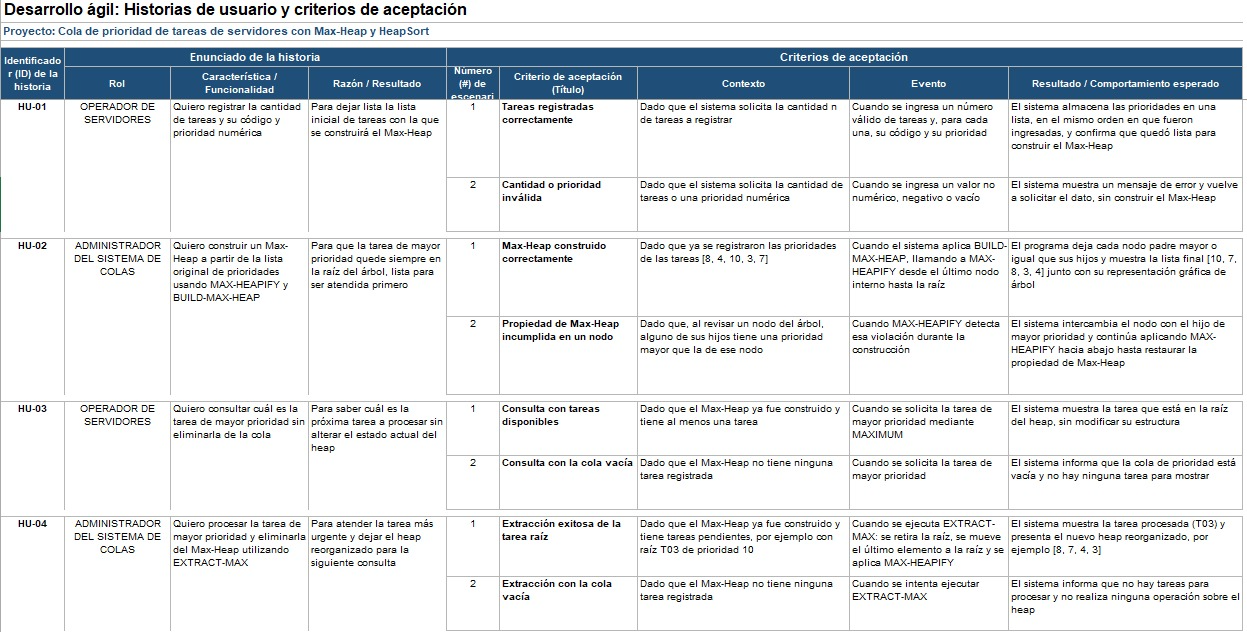



## 4) Diagramas de flujo **[5 pts]**
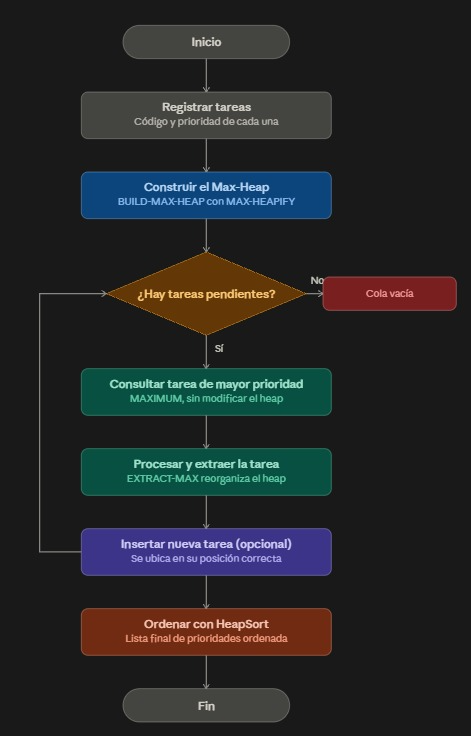


### 5) Análisis de complejidad **[15 pts]**
5.1. MAX-HEAPIFY

Complejidad: Mejor caso O(1), peor caso O(log n).

* Mejor caso: El nodo cumple la propiedad del Max-Heap y no necesita intercambios.
* Peor caso: El elemento debe descender varios niveles para recuperar la propiedad.

Función de tiempo:

* Mejor caso: T(n) = c
* Peor caso: T(n) = a log₂(n) + b

5.2. BUILD-MAX-HEAP

Complejidad: O(n) en ambos casos.

* Mejor caso: Los nodos ya cumplen la propiedad del Max-Heap.
* Peor caso: Es necesario reorganizar varios nodos del arreglo.

Función de tiempo:

T(n) = an + b

5.3. MAXIMUM

Complejidad: O(1) en ambos casos.

* Mejor caso: Se consulta directamente la raíz del Heap.
* Peor caso: También se accede directamente a la raíz, sin recorrer otros elementos.

Función de tiempo:

T(n) = c

5.4. EXTRACT-MAX

Complejidad: Mejor caso O(1), peor caso O(log n).

* Mejor caso: El elemento que reemplaza la raíz ya cumple la propiedad del Heap.
* Peor caso: El elemento debe descender varios niveles para reorganizar la estructura.

Función de tiempo:

* Mejor caso: T(n) = c
* Peor caso: T(n) = a log₂(n) + b

5.5. Inserción

Complejidad: Mejor caso O(1), peor caso O(log n).

* Mejor caso: La nueva tarea permanece en su posición inicial.
* Peor caso: La tarea asciende varios niveles hasta encontrar su posición correcta.

Función de tiempo:

* Mejor caso: T(n) = c
* Peor caso: T(n) = a log₂(n) + b

5.6. HEAPSORT

Complejidad: O(n log n) en ambos casos.

* Mejor caso: Las reorganizaciones requieren relativamente pocas operaciones, pero el algoritmo debe completar el ordenamiento.
* Peor caso: Se realizan reorganizaciones a lo largo de varios niveles durante las extracciones.

Función de tiempo:

T(n) = an log₂(n) + bn + c

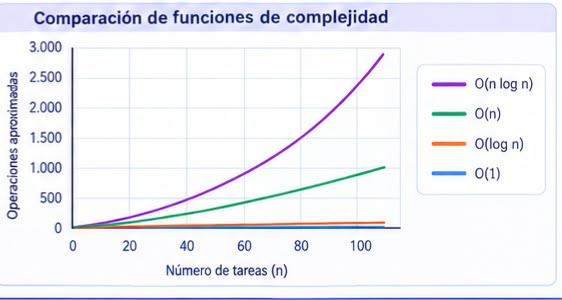
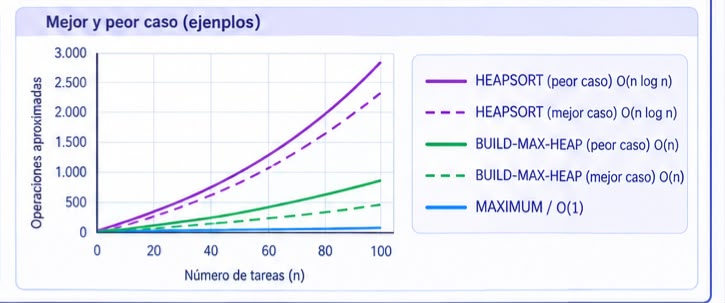

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
def registrar_tareas():
    """Solicita al usuario una cantidad de tareas y recoge sus datos."""
    cantidad = int(input("¿Cuántas tareas desea registrar? "))
    tareas = []
    for numero in range(cantidad):
        print(f"\nTarea {numero + 1}")
        codigo = input("Código: ")
        nombre = input("Nombre: ")
        prioridad = int(input("Prioridad (número entero): "))
        tareas.append({"codigo": codigo, "nombre": nombre, "prioridad": prioridad})
    return tareas




def max_heapify(heap, tamano, indice):
    """Corrige el subárbol cuya raíz está en indice para que sea Max-Heap."""
    mayor = indice
    izquierdo = 2 * indice + 1
    derecho = 2 * indice + 2

    if izquierdo < tamano and heap[izquierdo]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izquierdo
    if derecho < tamano and heap[derecho]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = derecho

    if mayor != indice:
        heap[indice], heap[mayor] = heap[mayor], heap[indice]

        max_heapify(heap, tamano, mayor)


def build_max_heap(elementos):
    """Convierte una lista de tareas en un Max-Heap, modificando esa lista."""
    tamano = len(elementos)
    ultimo_padre = tamano // 2 - 1
    for indice in range(ultimo_padre, -1, -1):
        max_heapify(elementos, tamano, indice)
    return elementos



def mostrar_arbol(heap):
    """Muestra los valores del heap por niveles, como un árbol sencillo."""
    if not heap:
        print("(heap vacío)")
        return

    inicio = 0
    cantidad_nivel = 1
    while inicio < len(heap):
        fin = min(inicio + cantidad_nivel, len(heap))
        valores = [str(t["prioridad"]) for t in heap[inicio:fin]]
        print("   " * max(0, (len(heap).bit_length() - cantidad_nivel.bit_length())) + "   ".join(valores))
        inicio = fin
        cantidad_nivel *= 2


def maximum(heap):
    """Devuelve la tarea de mayor prioridad sin eliminarla."""
    if len(heap) == 0:
        raise IndexError("No hay tareas en la cola de prioridad.")
    return heap[0]


def extract_max(heap):
    """Retira y devuelve la tarea con mayor prioridad."""
    if len(heap) == 0:
        raise IndexError("No hay tareas para procesar.")

    tarea_mayor = heap[0]
    ultimo = heap.pop()
    if heap:  
        heap[0] = ultimo
        max_heapify(heap, len(heap), 0)
    return tarea_mayor


def insertar(heap, nueva_tarea):
    
    tarea = nueva_tarea.copy()
    heap.append(tarea)
    indice = len(heap) - 1

    while indice > 0:
        padre = (indice - 1) // 2
        if heap[padre]["prioridad"] >= heap[indice]["prioridad"]:
            break
        heap[padre], heap[indice] = heap[indice], heap[padre]
        indice = padre



def heapsort(lista):
    """Devuelve una copia ordenada de menor a mayor mediante HeapSort."""
    arreglo = lista.copy()
    tamano = len(arreglo)

    
    for indice in range(tamano // 2 - 1, -1, -1):
        heapify_numeros(arreglo, tamano, indice)


    for ultimo in range(tamano - 1, 0, -1):
        arreglo[0], arreglo[ultimo] = arreglo[ultimo], arreglo[0]
        heapify_numeros(arreglo, ultimo, 0)
    return arreglo


def heapify_numeros(arreglo, tamano, indice):
    """Versión de MAX-HEAPIFY para una lista de números."""
    mayor = indice
    izquierdo = 2 * indice + 1
    derecho = 2 * indice + 2

    if izquierdo < tamano and arreglo[izquierdo] > arreglo[mayor]:
        mayor = izquierdo
    if derecho < tamano and arreglo[derecho] > arreglo[mayor]:
        mayor = derecho
    if mayor != indice:
        arreglo[indice], arreglo[mayor] = arreglo[mayor], arreglo[indice]
        heapify_numeros(arreglo, tamano, mayor)



def ejecutar_menu():
    tareas_usuario=registrar_tareas()
    prioridades_usuario=[t["prioridad"] for t in tareas_usuario]
    print("\nLista original de prioridades:",prioridades_usuario)
    heap_usuario=build_max_heap([t.copy() for t in tareas_usuario])
    print("Max-Heap construido:",[t["prioridad"] for t in heap_usuario])
    while True:
        print("\n--- MENÚ ---")
        print("1 Consultar mayor | 2 Procesar mayor | 3 Insertar tarea")
        print("4 Mostrar heap | 5 Mostrar árbol | 6 HeapSort | 0 Salir")
        opcion=input("Elija una opción: ").strip()
        if opcion=="1":
            try:
                t=maximum(heap_usuario)
                print(f'Tarea mayor: {t["codigo"]} - {t["nombre"]} - Prioridad {t["prioridad"]}')
            except IndexError as e: print(e)
        elif opcion=="2":
            try:
                t=extract_max(heap_usuario)
                print(f'Tarea procesada: {t["codigo"]} - {t["nombre"]} - Prioridad {t["prioridad"]}')
                print("Nuevo Heap:",[x["prioridad"] for x in heap_usuario])
            except IndexError as e: print(e)
        elif opcion=="3":
            nueva={"codigo":input("Código: ").strip(),"nombre":input("Nombre: ").strip(),"prioridad":int(input("Prioridad: "))}
            insertar(heap_usuario,nueva)
            print("Heap después de insertar:",[x["prioridad"] for x in heap_usuario])
        elif opcion=="4": print("Max-Heap:",[x["prioridad"] for x in heap_usuario])
        elif opcion=="5": mostrar_arbol(heap_usuario)
        elif opcion=="6": print("Lista original:",prioridades_usuario,"\nLista ordenada:",heapsort(prioridades_usuario))
        elif opcion=="0":
            print("Programa finalizado por decisión del usuario.")
            break
        else: print("Opción no válida. Intente nuevamente.")

ejecutar_menu()


¿Cuántas tareas desea registrar? 
Tarea 1
Código: Nombre: Prioridad (número entero): 
Tarea 2
Código: Nombre: Prioridad (número entero): 
Tarea 3
Código: Nombre: Prioridad (número entero): 
Tarea 4
Código: Nombre: Prioridad (número entero): 
Tarea 5
Código: Nombre: Prioridad (número entero): 
Tarea 6
Código: Nombre: Prioridad (número entero): 
Lista original de prioridades: [8, 4, 10, 3, 7, 12]
Max-Heap construido: [12, 7, 10, 3, 4, 8]

--- MENÚ ---
1 Consultar mayor | 2 Procesar mayor | 3 Insertar tarea
4 Mostrar heap | 5 Mostrar árbol | 6 HeapSort | 0 Salir
Elija una opción: Tarea mayor: T06 - Actualizar servidor - Prioridad 12

--- MENÚ ---
1 Consultar mayor | 2 Procesar mayor | 3 Insertar tarea
4 Mostrar heap | 5 Mostrar árbol | 6 HeapSort | 0 Salir
Elija una opción: Tarea procesada: T06 - Actualizar servidor - Prioridad 12
Nuevo Heap: [10, 7, 8, 3, 4]

--- MENÚ ---
1 Consultar mayor | 2 Procesar mayor | 3 Insertar tarea
4 Mostrar heap | 5 Mostrar árbol | 6 HeapSort | 0 Salir
Elija

## 7) Tests aplicados **[15 pts]**

In [ ]:

tareas_prueba=[{"codigo":"T01","nombre":"Compilar","prioridad":8},{"codigo":"T02","nombre":"Backup","prioridad":4},{"codigo":"T03","nombre":"Video","prioridad":10},{"codigo":"T04","nombre":"Correos","prioridad":3},{"codigo":"T05","nombre":"Pruebas","prioridad":7},{"codigo":"T06","nombre":"Servidor","prioridad":12}]
prioridades_prueba=[t["prioridad"] for t in tareas_prueba]
def es_max_heap(h): return all(h[(i-1)//2]["prioridad"]>=h[i]["prioridad"] for i in range(1,len(h)))
resultados=[]
def ejecutar(nombre,datos,accion,funcion):
    try: obtenido=funcion(); estado="APROBADA"
    except Exception as e: obtenido=f"{type(e).__name__}: {e}"; estado="FALLIDA"
    resultados.append((estado,nombre,datos,accion,str(obtenido)))
    print(f"{estado} — {nombre}\n Datos usados: {datos}\n Acción: {accion}\n Resultado: {obtenido}\n")
def test_registro():
    assert len(tareas_prueba)==6 and prioridades_prueba==[8,4,10,3,7,12]
    return f"6 tareas conservadas en el orden ingresado: {prioridades_prueba}"
def test_build():
    h=build_max_heap([t.copy() for t in tareas_prueba]); assert es_max_heap(h) and maximum(h)["prioridad"]==12
    return f"Max-Heap obtenido: {[t['prioridad'] for t in h]}"
def test_max():
    h=build_max_heap([t.copy() for t in tareas_prueba]); antes=len(h); t=maximum(h)
    assert t["prioridad"]==12 and len(h)==antes
    return f"Consultó {t['codigo']} prioridad 12; el heap mantiene {len(h)} elementos"
def test_extract():
    h=build_max_heap([t.copy() for t in tareas_prueba]); t=extract_max(h)
    assert t["prioridad"]==12 and es_max_heap(h)
    return f"Procesó {t['codigo']} prioridad 12; nuevo heap: {[x['prioridad'] for x in h]}"
def test_insert():
    h=build_max_heap([t.copy() for t in tareas_prueba]); insertar(h,{"codigo":"TX","nombre":"Prueba","prioridad":20})
    assert maximum(h)["prioridad"]==20 and es_max_heap(h)
    return f"Insertó TX prioridad 20; raíz actual: {maximum(h)['prioridad']}"
def test_sort():
    orden=heapsort(prioridades_prueba); assert orden==[3,4,7,8,10,12] and prioridades_prueba==[8,4,10,3,7,12]
    return f"Lista inicial {prioridades_prueba} -> lista ordenada {orden}"
def test_empty():
    errores=[]
    for f in (maximum,extract_max):
        try: f([])
        except IndexError as e: errores.append(str(e))
    assert len(errores)==2
    return "MAXIMUM y EXTRACT-MAX detectaron correctamente heap vacío"
casos=[("Registro","6 tareas; prioridades [8,4,10,3,7,12]","Guardar orden ingresado",test_registro),("BUILD-MAX-HEAP","Seis tareas de ejemplo","Construir heap; verificar padre >= hijos",test_build),("MAXIMUM","Heap con raíz 12","Consultar sin eliminar",test_max),("EXTRACT-MAX","Heap con raíz 12","Retirar máximo y reorganizar",test_extract),("Inserción","Agregar TX con prioridad 20","Insertar y subir a la raíz",test_insert),("HeapSort","[8,4,10,3,7,12]","Ordenar ascendente conservando original",test_sort),("Heap vacío","Arreglo []","Consultar y extraer",test_empty)]
for caso in casos: ejecutar(*caso)
aprobadas=sum(1 for r in resultados if r[0]=="APROBADA")
print(f"RESUMEN: {aprobadas} de {len(casos)} pruebas aprobadas")


APROBADA — Registro
 Datos usados: 6 tareas; prioridades [8,4,10,3,7,12]
 Acción: Guardar orden ingresado
 Resultado: 6 tareas conservadas en el orden ingresado: [8, 4, 10, 3, 7, 12]

APROBADA — BUILD-MAX-HEAP
 Datos usados: Seis tareas de ejemplo
 Acción: Construir heap; verificar padre >= hijos
 Resultado: Max-Heap obtenido: [12, 7, 10, 3, 4, 8]

APROBADA — MAXIMUM
 Datos usados: Heap con raíz 12
 Acción: Consultar sin eliminar
 Resultado: Consultó T06 prioridad 12; el heap mantiene 6 elementos

APROBADA — EXTRACT-MAX
 Datos usados: Heap con raíz 12
 Acción: Retirar máximo y reorganizar
 Resultado: Procesó T06 prioridad 12; nuevo heap: [10, 7, 8, 3, 4]

APROBADA — Inserción
 Datos usados: Agregar TX con prioridad 20
 Acción: Insertar y subir a la raíz
 Resultado: Insertó TX prioridad 20; raíz actual: 20

APROBADA — HeapSort
 Datos usados: [8,4,10,3,7,12]
 Acción: Ordenar ascendente conservando original
 Resultado: Lista inicial [8, 4, 10, 3, 7, 12] -> lista ordenada [3, 4, 7, 8, 10, 